## Setup

Keep [`example_data.py`](example_data.py) and [`data_fidelity_metrics.py`](data_fidelity_metrics.py) beside this notebook. The project environment supplies NumPy, pandas, Matplotlib, and IPython.

In [17]:
#| label: setup

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from data_fidelity_metrics import (
    NUMERIC_HELLINGER_BINS,
    categorical_probability_vectors,
    empirical_feature_hellinger_details,
    empirical_feature_hellinger_distance,
    hellinger_distance,
    numeric_probability_vectors,
)
from example_data import (
    METRIC_CATEGORICAL_COLUMNS,
    METRIC_NUMERIC_COLUMNS,
    make_example_views,
)

## Learning goals

By the end of this lesson, you should be able to:

- explain what the average empirical Hellinger distance measures;
- align categorical levels and numerical histogram bins across two tables;
- calculate one Hellinger distance for each transformed column;
- average the column distances into one data-fidelity score; and
- interpret small and large values without treating the score as a percentage.

## 1. Metric and complete inputs

The **Average Empirical Hellinger Distance** is a data-fidelity metric. We write it as $\mathrm{Hel}_{\mathrm{fidelity}}$. It compares the distribution of each column in the complete mixed-type tables $\widetilde X$ and $\widetilde Y$. It then averages the column results.

Unlike the Correlation Matrix Difference, this metric examines one column at a time. It does not measure relationships between columns. It allows $\widetilde X$ and $\widetilde Y$ to have different numbers of rows.

We use the same complete preprocessed tables as the previous lessons. They have four categorical columns and two numerical columns. Therefore, $\widetilde d=6$, and the metric compares six columns.

In [18]:
#| label: complete-inputs

example = make_example_views()
X_tilde, Y_tilde = example.X_tilde, example.Y_tilde

print("X_tilde")
display(X_tilde)
print("Y_tilde")
display(Y_tilde)

X_tilde


,age,age__missing,income_k,income_k__missing,region__code,outcome
x1,0.000000,0,0.000000,0,1,0
x2,0.194444,0,0.271186,0,2,0
x3,0.416667,1,0.389831,0,1,1
x4,0.611111,0,0.389831,1,3,1
x5,0.944444,0,1.000000,0,4,1
x6,0.416667,0,0.593220,0,2,0


Y_tilde


,age,age__missing,income_k,income_k__missing,region__code,outcome
y1,0.027778,0,0.050847,0,1,0
y2,0.416667,1,0.322034,0,2,1
y3,0.555556,0,0.389831,1,3,1
y4,1.000000,0,0.949153,0,4,1
y5,0.361111,0,0.542373,0,0,0


## 2. Hellinger distance for one column

For column $j$, let $p^X_{jb}$ and $p^Y_{jb}$ be the empirical probabilities of category or bin $b$ in $\widetilde X$ and $\widetilde Y$. Both probability vectors must use the same ordered support. Let $B_j$ be the number of aligned categories or bins. The Hellinger distance for column $j$ is

$$
H_j(\widetilde X,\widetilde Y)=
\sqrt{\frac12\sum_{b=1}^{B_j}
\left(\sqrt{p^X_{jb}}-\sqrt{p^Y_{jb}}\right)^2}
$$

The distance is always between $0$ and $1$. A value of $0$ means the two probability vectors are identical. A small value means their distributions are similar. A large value means their distributions are different. A value of $1$ means their observed supports do not overlap.

In [19]:
#| label: hellinger-range-examples

same_distribution = hellinger_distance(
    np.array([0.5, 0.5]),
    np.array([0.5, 0.5]),
)
disjoint_distributions = hellinger_distance(
    np.array([1.0, 0.0]),
    np.array([0.0, 1.0]),
)

print(f"Identical distributions: H = {same_distribution:.1f}")
print(f"Disjoint distributions: H = {disjoint_distributions:.1f}")

Identical distributions: H = 0.0
Disjoint distributions: H = 1.0


## 3. Categorical columns: align all observed levels

For a categorical column $j$, use the union of levels observed in both tables. Call the aligned levels $s_{j1},\ldots,s_{jB_j}$. The empirical probabilities are the proportions of rows in each level:

$$
p^X_{jb}=\frac{1}{n_X}\sum_{i=1}^{n_X}
\mathbf 1\{\widetilde x_{ij}=s_{jb}\},
\qquad
p^Y_{jb}=\frac{1}{n_Y}\sum_{i=1}^{n_Y}
\mathbf 1\{\widetilde y_{ij}=s_{jb}\}
$$

A level that is missing from one table receives probability $0$ in that table. This alignment is required before applying the Hellinger formula.

The next cell uses `region__code`. The codes are category labels here. They are not treated as numerical quantities.

In [20]:
#| label: categorical-hellinger-example

region_levels, region_p_X, region_p_Y = categorical_probability_vectors(
    X_tilde["region__code"],
    Y_tilde["region__code"],
)
region_probabilities = pd.DataFrame(
    {
        "region code": region_levels,
        "p_X": region_p_X,
        "p_Y": region_p_Y,
    }
)
H_region = hellinger_distance(region_p_X, region_p_Y)

display(region_probabilities.round(4))
print(f"H_region = {H_region:.6f}")

,region code,p_X,p_Y
0,0,0.0000,0.2
1,1,0.3333,0.2
2,2,0.3333,0.2
3,3,0.1667,0.2
4,4,0.1667,0.2


H_region = 0.344171


## 4. Numerical columns: use shared histogram bins

A numerical column has many possible values. We first convert it into a histogram. The implementation uses ten equal-width bins. The bin range starts at the pooled minimum and ends at the pooled maximum across both tables.

Both tables use the same bin edges. We count the values in each bin and divide by the table's row count. This produces two aligned probability vectors. We then apply the same Hellinger formula.

Shared bins are important. Separate bin edges would compare different numerical intervals and would give a misleading result.

In [21]:
#| label: numerical-hellinger-example

age_edges, age_p_X, age_p_Y = numeric_probability_vectors(
    X_tilde["age"],
    Y_tilde["age"],
    bins=NUMERIC_HELLINGER_BINS,
)
age_bin_labels = []
for index, (left, right) in enumerate(zip(age_edges[:-1], age_edges[1:])):
    closing = "]" if index == len(age_edges) - 2 else ")"
    age_bin_labels.append(f"[{left:.3f}, {right:.3f}{closing}")

age_probabilities = pd.DataFrame(
    {
        "shared age bin": age_bin_labels,
        "p_X": age_p_X,
        "p_Y": age_p_Y,
    }
)
H_age = hellinger_distance(age_p_X, age_p_Y)

display(age_probabilities.round(4))
print(f"H_age = {H_age:.6f}")

,shared age bin,p_X,p_Y
0,"[0.000, 0.100)",0.1667,0.2
1,"[0.100, 0.200)",0.1667,0.0
2,"[0.200, 0.300)",0.0000,0.0
3,"[0.300, 0.400)",0.0000,0.2
4,"[0.400, 0.500)",0.3333,0.2
5,"[0.500, 0.600)",0.0000,0.2
6,"[0.600, 0.700)",0.1667,0.0
7,"[0.700, 0.800)",0.0000,0.0
8,"[0.800, 0.900)",0.0000,0.0
9,"[0.900, 1.000]",0.1667,0.2


H_age = 0.613720


## 5. Average across all columns

Let $\widetilde d$ be the total number of columns in each complete preprocessed table. Calculate one distance $H_j$ for each column. The Average Empirical Hellinger Distance is

$$
\mathrm{Hel}_{\mathrm{fidelity}}(X,Y)=
\frac1{\widetilde d}\sum_{j=1}^{\widetilde d}H_j(\widetilde X,\widetilde Y)
$$

Every preprocessed column receives the same weight. A categorical column and a numerical column each contribute one value to the average. Here $\widetilde d=6$, so the metric is the mean of six column distances.

In [22]:
#| label: calculate-average-empirical-hellinger

details = empirical_feature_hellinger_details(
    X_tilde,
    Y_tilde,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
    numeric_columns=METRIC_NUMERIC_COLUMNS,
)
Hel_fidelity = empirical_feature_hellinger_distance(
    X_tilde,
    Y_tilde,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
    numeric_columns=METRIC_NUMERIC_COLUMNS,
)

display(details.round(4))
print(f"Average empirical Hellinger distance = {Hel_fidelity:.6f}")
assert np.isclose(Hel_fidelity, details["distance"].mean())

,column,type,distance
0,region__code,categorical,0.3442
1,age__missing,categorical,0.0305
2,income_k__missing,categorical,0.0305
3,outcome,categorical,0.0712
4,age,numerical,0.6137
5,income_k,numerical,0.2952


Average empirical Hellinger distance = 0.230866


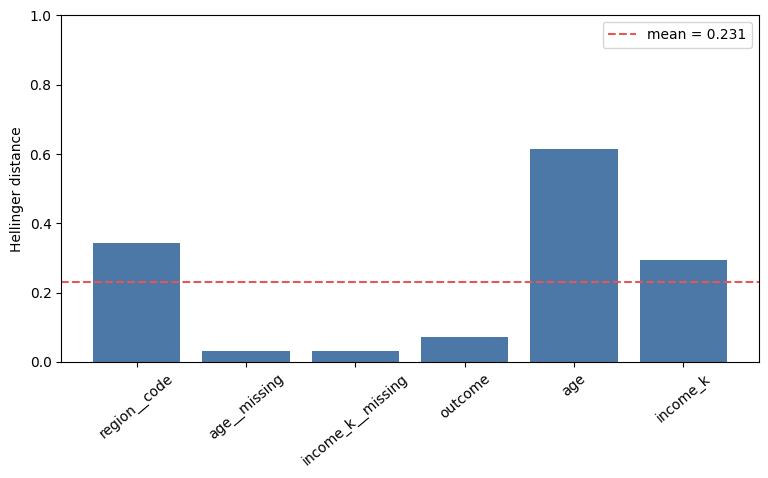

In [23]:
#| label: fig-feature-hellinger
#| fig-cap: "Per-column Hellinger distances whose arithmetic mean is the reported metric."

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(details["column"], details["distance"], color="#4c78a8")
ax.axhline(
    Hel_fidelity,
    color="#e45756",
    linestyle="--",
    label=f"mean = {Hel_fidelity:.3f}",
)
ax.set(ylabel="Hellinger distance", ylim=(0, 1))
ax.tick_params(axis="x", rotation=40)
ax.legend()
plt.show()

In [24]:
#| label: metric-sanity-checks

Hel_fidelity_same = empirical_feature_hellinger_distance(
    X_tilde,
    X_tilde,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
    numeric_columns=METRIC_NUMERIC_COLUMNS,
)
Hel_fidelity_reversed = empirical_feature_hellinger_distance(
    Y_tilde,
    X_tilde,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
    numeric_columns=METRIC_NUMERIC_COLUMNS,
)

print(f"Hel_fidelity(X, X) = {Hel_fidelity_same:.6f}")
print(f"Hel_fidelity(Y, X) = {Hel_fidelity_reversed:.6f}")
assert np.isclose(Hel_fidelity_same, 0.0)
assert np.isclose(Hel_fidelity, Hel_fidelity_reversed)
assert 0.0 <= Hel_fidelity <= 1.0
assert np.isclose(Hel_fidelity, 0.23086604160516105)

Hel_fidelity(X, X) = 0.000000
Hel_fidelity(Y, X) = 0.230866


## 6. Interpretation

For the shared example, $\mathrm{Hel}_{\mathrm{fidelity}}(X,Y)\approx0.2309$. This is the mean of the six column distances. It does not mean that the tables are $23.09\%$ different.

- A value of $0$ means every compared column has the same empirical distribution in both tables. It does not mean the tables are identical.
- A small value means the column distributions are similar overall.
- A large value means the column distributions are different overall.
- A value of $1$ means every compared column has disjoint empirical support.
- The metric is symmetric. Swapping the two tables does not change it.
- The metric compares marginal distributions only. It can miss differences in relationships between columns.

In this example, `age` has the largest column distance. The two missingness indicators have the smallest distances. The final score is most useful when comparing several versions of $Y$ against the same $X$ with the same columns, transformation, and binning rules.

## Takeaway

The Average Empirical Hellinger Distance follows four steps:

1. align the categories or numerical bins for each column;
2. convert the aligned counts into probabilities;
3. calculate one Hellinger distance per column; and
4. average the column distances.

A smaller result means the two tables have more similar column distributions. Use the Correlation Matrix Difference as a companion metric when relationships between columns also matter.